<h1><center> XGBoost with make_classification

In [83]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

In [84]:
X, y = make_classification(
                            n_samples= 500,
                            n_features= 5,
                            n_informative= 3,
                            n_redundant= 0,
                            random_state= 42
)


In [85]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)
print(len(X_train), len(y_train))
print(len(X_test), len(y_test))

400 400
100 100


#### First experiment using Decison Tree :

In [86]:
model_DT = DecisionTreeClassifier(criterion='gini')
model_DT.fit(X_train, y_train)

DecisionTreeClassifier()

In [87]:
y_pred_DT = model_DT.predict(X_test)

Accuracy :  0.93
Classification report : 
               precision    recall  f1-score   support

           0       0.91      0.96      0.93        50
           1       0.96      0.90      0.93        50

    accuracy                           0.93       100
   macro avg       0.93      0.93      0.93       100
weighted avg       0.93      0.93      0.93       100



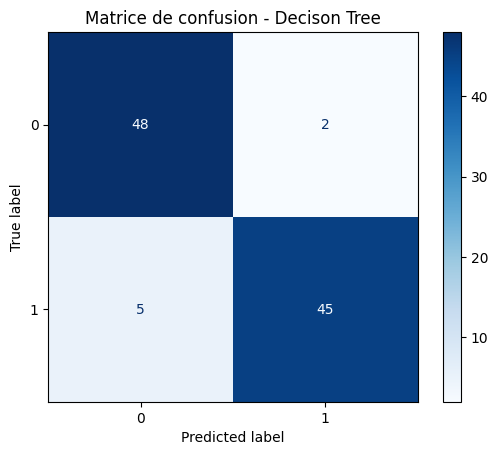

In [88]:
print("Accuracy : ", accuracy_score(y_test, y_pred_DT))
print("Classification report : \n", classification_report(y_test, y_pred_DT))
conf_DT = confusion_matrix(y_test, y_pred_DT)
disp = ConfusionMatrixDisplay(conf_DT)
disp.plot(cmap='Blues')
plt.title("Matrice de confusion - Decison Tree")
plt.show()

#### Second experiment using Random Forest :

In [89]:
model_RF = RandomForestClassifier(n_estimators=100, criterion= 'gini')
model_RF.fit(X_train, y_train)

RandomForestClassifier()

In [90]:
y_pred_RF = model_RF.predict(X_test)

Accuracy :  0.93
Classification report : 
               precision    recall  f1-score   support

           0       0.91      0.96      0.93        50
           1       0.96      0.90      0.93        50

    accuracy                           0.93       100
   macro avg       0.93      0.93      0.93       100
weighted avg       0.93      0.93      0.93       100



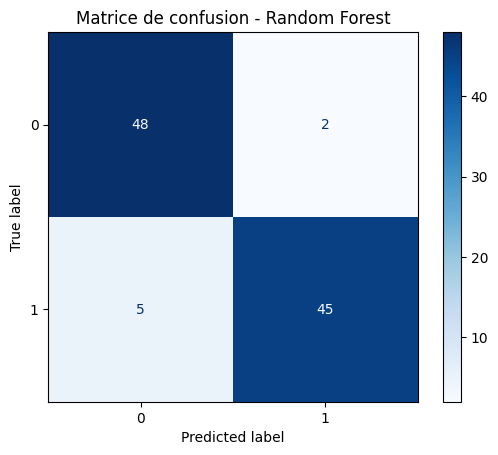

In [91]:
print("Accuracy : ", accuracy_score(y_test, y_pred_RF))
print("Classification report : \n", classification_report(y_test, y_pred_RF))
conf_RF = confusion_matrix(y_test, y_pred_RF)
disp = ConfusionMatrixDisplay(conf_RF)
disp.plot(cmap='Blues')
plt.title("Matrice de confusion - Random Forest")
plt.show()

#### Third experiment using XGBoost:

In [92]:
model = XGBClassifier(
    n_estimators=100,      # nombre d'arbres
    learning_rate=0.1,     # taux d'apprentissage
    max_depth=3,           # profondeur des arbres
    subsample=0.8,         # fraction d'échantillons par arbre
    colsample_bytree=0.8,  # fraction de features par arbre
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Accuracy :  0.95
Classification report : 
               precision    recall  f1-score   support

           0       0.94      0.96      0.95        50
           1       0.96      0.94      0.95        50

    accuracy                           0.95       100
   macro avg       0.95      0.95      0.95       100
weighted avg       0.95      0.95      0.95       100



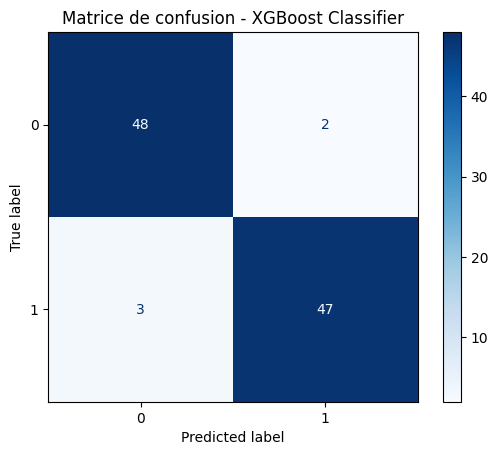

In [93]:

print("Accuracy : ", accuracy_score(y_test, y_pred))
print("Classification report : \n", classification_report(y_test, y_pred))
conf_XGb = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(conf_XGb)
disp.plot(cmap='Blues')
plt.title("Matrice de confusion - XGBoost Classifier")
plt.show()

<h1><center> FIN